<a href="https://colab.research.google.com/github/Alvacampos/Alvacampos/blob/main/EDA_default_tarjetas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA – Default of Credit Card Clients

**Fuente:** UCI Machine Learning Repository (id 350). Yeh, I. C. & Lien, C. H. (2009).
**Contenido:** 30.000 clientes de tarjetas de crédito en Taiwán (abril–septiembre 2005), con 23 variables explicativas y 1 variable objetivo.

**Pregunta de negocio:** ¿Es posible anticipar qué clientes entrarán en default el mes siguiente?

**Justificación:** el dataset admite los tres enfoques que pide la consigna:
- **Clasificación:** predecir el default (variable binaria).
- **Regresión:** estimar el límite de crédito (`LIMIT_BAL`).
- **Clustering:** segmentar clientes según su comportamiento de pago.

In [14]:
!pip install ucimlrepo -q
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo

data = fetch_ucirepo(id=350)
df = pd.concat([data.data.features, data.data.targets], axis=1)

# UCI entrega las columnas como X1..X23 y Y; las renombro con nombres descriptivos
nombres = (['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE'] +
           [f'PAY_{i}' for i in range(1, 7)] +        # estado de pago: 1=sep ... 6=abr
           [f'BILL_AMT{i}' for i in range(1, 7)] +    # monto facturado
           [f'PAY_AMT{i}' for i in range(1, 7)] +     # monto pagado
           ['DEFAULT'])
df.columns = nombres

print(df.shape)
df.head()

(30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [15]:
df.info()

tipos = {
    'LIMIT_BAL': 'Numérica continua', 'AGE': 'Numérica discreta',
    'SEX': 'Categórica nominal', 'MARRIAGE': 'Categórica nominal',
    'EDUCATION': 'Categórica ordinal', 'DEFAULT': 'Binaria (objetivo)',
    **{f'PAY_{i}': 'Categórica ordinal' for i in range(1, 7)},
    **{f'BILL_AMT{i}': 'Numérica continua' for i in range(1, 7)},
    **{f'PAY_AMT{i}': 'Numérica continua' for i in range(1, 7)},
}
resumen = pd.DataFrame({
    'dtype_pandas': df.dtypes,
    'tipo_semantico': pd.Series(tipos),
    'valores_unicos': df.nunique(),
})
resumen

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   LIMIT_BAL  30000 non-null  int64
 1   SEX        30000 non-null  int64
 2   EDUCATION  30000 non-null  int64
 3   MARRIAGE   30000 non-null  int64
 4   AGE        30000 non-null  int64
 5   PAY_1      30000 non-null  int64
 6   PAY_2      30000 non-null  int64
 7   PAY_3      30000 non-null  int64
 8   PAY_4      30000 non-null  int64
 9   PAY_5      30000 non-null  int64
 10  PAY_6      30000 non-null  int64
 11  BILL_AMT1  30000 non-null  int64
 12  BILL_AMT2  30000 non-null  int64
 13  BILL_AMT3  30000 non-null  int64
 14  BILL_AMT4  30000 non-null  int64
 15  BILL_AMT5  30000 non-null  int64
 16  BILL_AMT6  30000 non-null  int64
 17  PAY_AMT1   30000 non-null  int64
 18  PAY_AMT2   30000 non-null  int64
 19  PAY_AMT3   30000 non-null  int64
 20  PAY_AMT4   30000 non-null  int64
 21  PAY_AMT5   3

,dtype_pandas,tipo_semantico,valores_unicos
AGE,int64,Numérica discreta,56
BILL_AMT1,int64,Numérica continua,22723
BILL_AMT2,int64,Numérica continua,22346
BILL_AMT3,int64,Numérica continua,22026
BILL_AMT4,int64,Numérica continua,21548
BILL_AMT5,int64,Numérica continua,21010
BILL_AMT6,int64,Numérica continua,20604
DEFAULT,int64,Binaria (objetivo),2
EDUCATION,int64,Categórica ordinal,7
LIMIT_BAL,int64,Numérica continua,81


Todas las columnas vienen como int64, pero no todas son números "de verdad". SEX, EDUCATION,
MARRIAGE y PAY_1 a PAY_6 son códigos de categorías, así que no tiene sentido hacer cuentas
con ellos. Por ejemplo, EDUCATION = 4 no es el doble de EDUCATION = 2.

Las variables se pueden separar en 4 grupos:
- Datos del cliente: límite de crédito, sexo, educación, estado civil y edad.
- Estado de pago de cada mes, de abril a septiembre (-1 es pago al día y de 1 a 9 son meses de atraso).
- Montos facturados y montos pagados de cada mes, en dólares taiwaneses.
- DEFAULT, que es lo que quiero predecir: si el cliente no paga el mes siguiente.

In [16]:
print("Valores nulos totales:", df.isnull().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())

Valores nulos totales: 0
Filas duplicadas: 35


In [17]:
for col in ['EDUCATION', 'MARRIAGE', 'PAY_1']:
    print(col, df[col].value_counts().sort_index().to_dict())

EDUCATION {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE {0: 54, 1: 13659, 2: 15964, 3: 323}
PAY_1 {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}


In [18]:
bill = [f'BILL_AMT{i}' for i in range(1, 7)]
print("Facturas negativas por mes:\n", (df[bill] < 0).sum())
print("\nClientes con deuda > límite (sep):", (df['BILL_AMT1'] > df['LIMIT_BAL']).sum())

Facturas negativas por mes:
 BILL_AMT1    590
BILL_AMT2    669
BILL_AMT3    655
BILL_AMT4    675
BILL_AMT5    655
BILL_AMT6    688
dtype: int64

Clientes con deuda > límite (sep): 2115


{'LIMIT_BAL': np.int64(167), 'AGE': np.int64(272), 'BILL_AMT1': np.int64(2400), 'PAY_AMT1': np.int64(2745)}


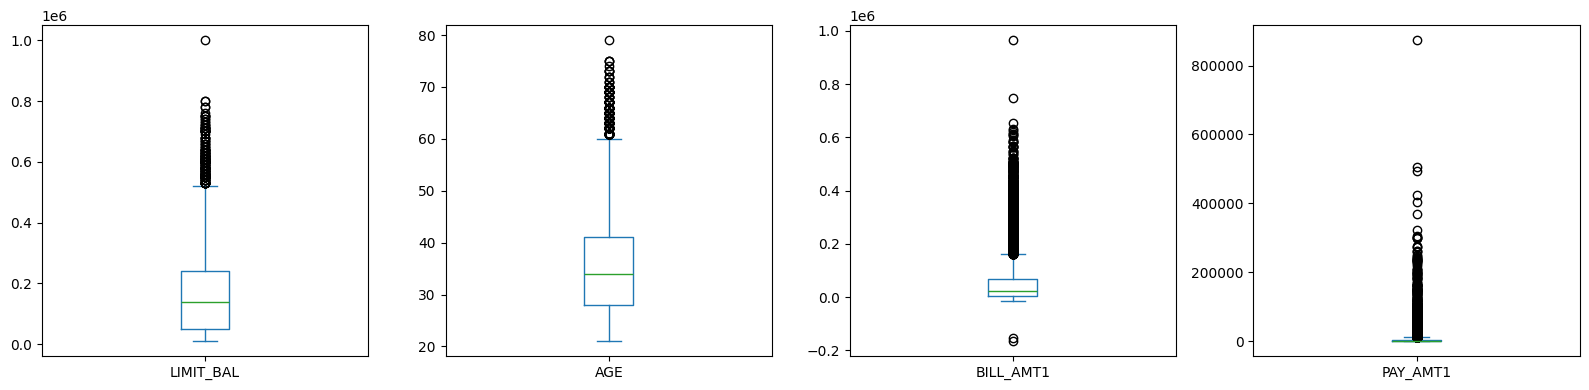

In [19]:
import matplotlib.pyplot as plt

def outliers_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

num = ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'PAY_AMT1']
print({c: outliers_iqr(df[c]) for c in num})

df[num].plot(kind='box', subplots=True, layout=(1, 4), figsize=(16, 4))
plt.tight_layout()
plt.show()

No hay valores nulos, así que no hace falta completar nada. Aparecen 35 filas duplicadas (0,12%).
Como el dataset no tiene un ID de cliente, pueden ser personas distintas con los mismos datos,
así que las dejo.

Lo que sí encontré son códigos que no figuran en la documentación:
- EDUCATION tiene 0, 5 y 6 (345 registros, un 1%). Los voy a agrupar en 4, que es "otros".
- MARRIAGE tiene 0 (54 registros). Lo voy a agrupar en 3, que también es "otros".
- PAY_1 tiene -2 y 0 en el 58% de los registros. Con tantos casos no pueden ser errores, así que
  los tomo como categorías válidas. Según la interpretación que más se usa, -2 sería sin consumo
  y 0 sería pago mínimo.

También hay facturas negativas (un 2% por mes), que entiendo que son saldo a favor, y 2.115
clientes que deben más que su límite. Las dos cosas pasan en tarjetas de crédito, así que no las toco.

En los montos hay bastantes outliers (8-9% en BILL_AMT1 y PAY_AMT1), pero no los saco: son
clientes que gastan o pagan mucho, no errores de carga.

In [20]:
# Resumen Estadistico
df[['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'PAY_AMT1']].describe().round(0)

,LIMIT_BAL,AGE,BILL_AMT1,PAY_AMT1
count,30000.0,30000.0,30000.0,30000.0
mean,167484.0,35.0,51223.0,5664.0
std,129748.0,9.0,73636.0,16563.0
min,10000.0,21.0,-165580.0,0.0
25%,50000.0,28.0,3559.0,1000.0
50%,140000.0,34.0,22382.0,2100.0
75%,240000.0,41.0,67091.0,5006.0
max,1000000.0,79.0,964511.0,873552.0


DEFAULT
0    0.779
1    0.221
Name: proportion, dtype: float64


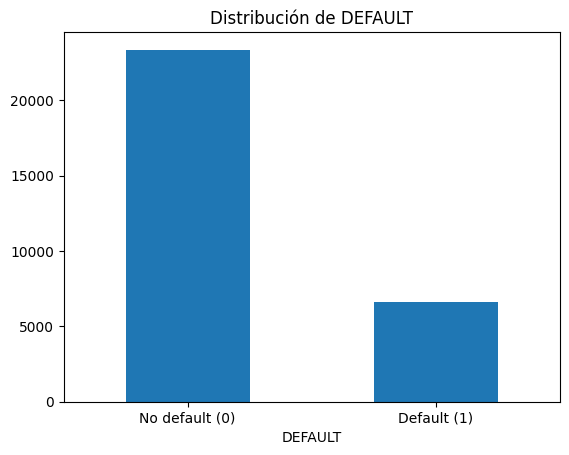

In [21]:
# Variable objetivo
print(df['DEFAULT'].value_counts(normalize=True).round(3))

df['DEFAULT'].value_counts().plot(kind='bar', title='Distribución de DEFAULT')
plt.xticks([0, 1], ['No default (0)', 'Default (1)'], rotation=0)
plt.show()

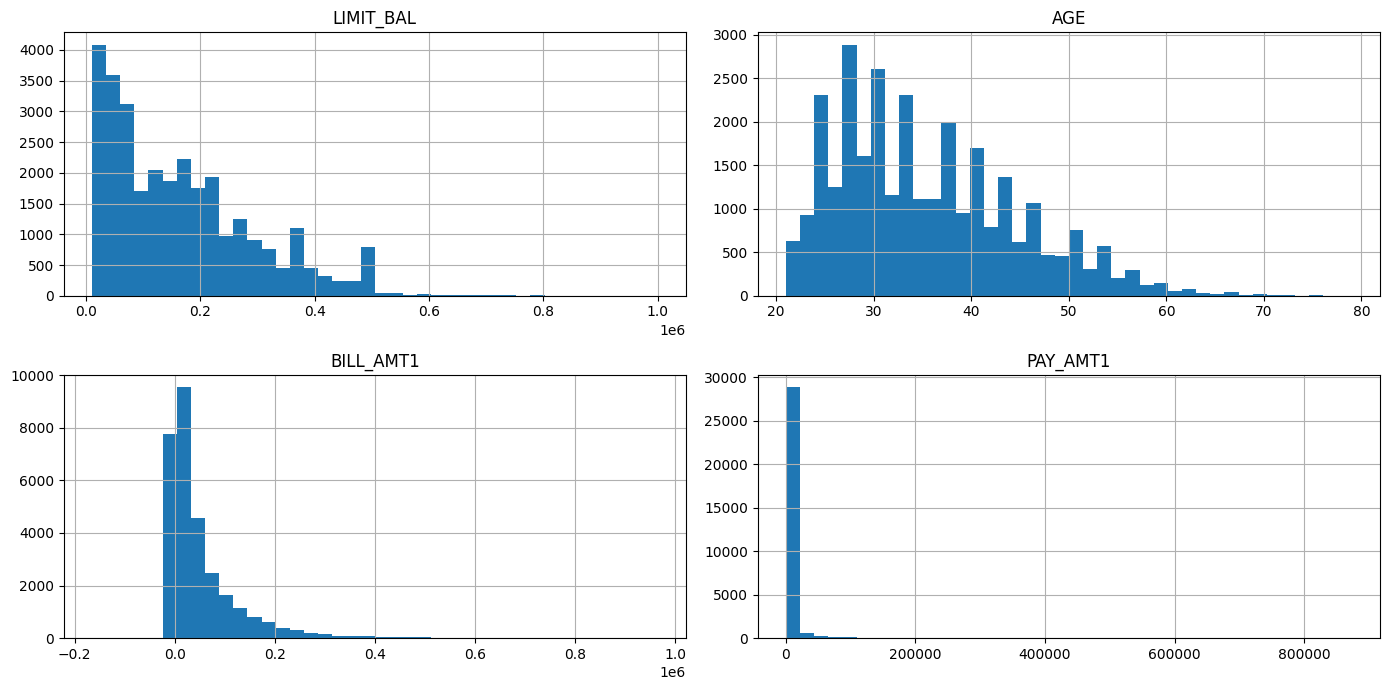

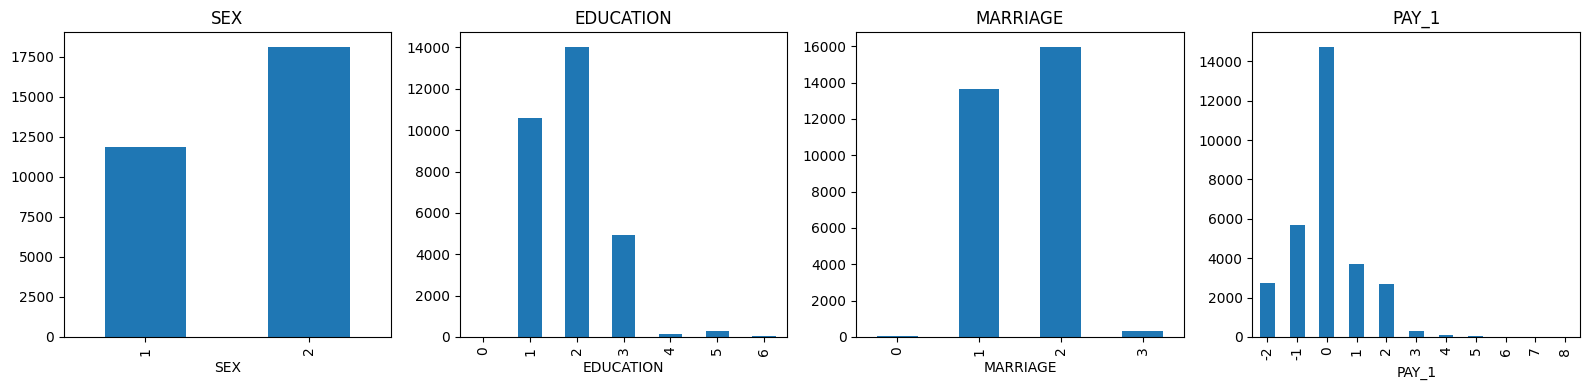

In [22]:

# Numéricas: histogramas
df[['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'PAY_AMT1']].hist(bins=40, figsize=(14, 7))
plt.tight_layout()
plt.show()

# Categóricas: barras
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_1']):
    df[col].value_counts().sort_index().plot(kind='bar', ax=ax, title=col)
plt.tight_layout()
plt.show()

El 22% de los clientes hizo default y el 78% no. Las clases están bastante desbalanceadas, así que
para evaluar el modelo no me sirve la accuracy: si predice siempre "no default", ya acierta el 78%.

En los montos (LIMIT_BAL, BILL_AMT1 y PAY_AMT1) la media es mucho más alta que la mediana; en
PAY_AMT1 es casi el triple. O sea, la mayoría tiene montos bajos y unos pocos tienen montos muy
altos que suben el promedio. Antes de modelar puede convenir aplicarles logaritmo.

La mitad de los clientes tiene entre 28 y 41 años. Hay más mujeres (60%), la mayoría tiene
universidad o posgrado (82%), y solteros y casados están casi parejos.

En PAY_1, la mitad tiene código 0 y un 23% tiene por lo menos un mes de atraso. Es casi el mismo
porcentaje que el de default, así que en el siguiente punto miro si tienen relación.

PAY_1        0.325
PAY_2        0.264
PAY_3        0.235
AGE          0.014
BILL_AMT3   -0.014
BILL_AMT2   -0.014
BILL_AMT1   -0.020
PAY_AMT2    -0.059
PAY_AMT1    -0.073
LIMIT_BAL   -0.154
Name: DEFAULT, dtype: float64


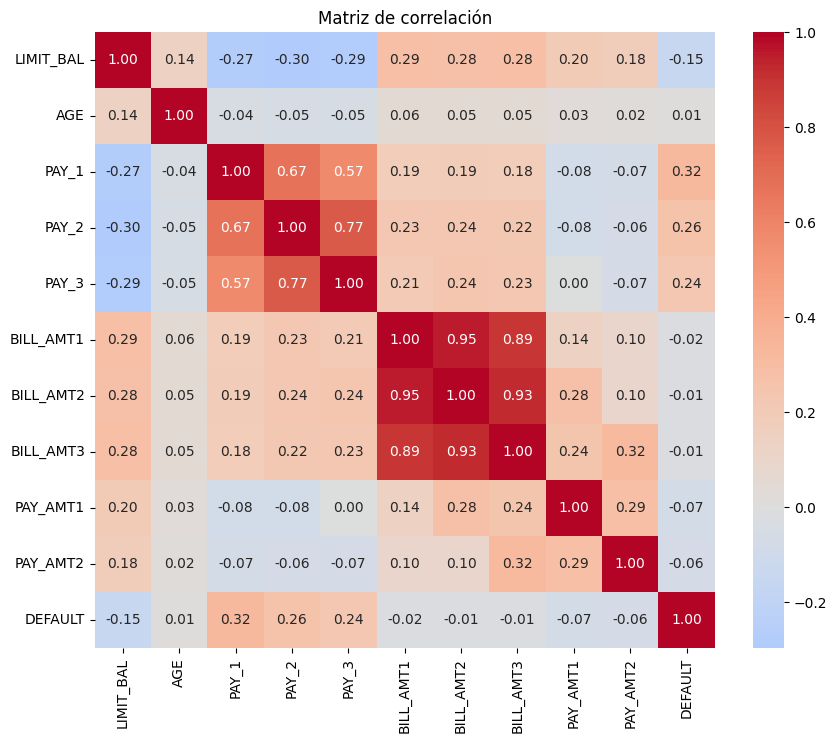

In [23]:
import seaborn as sns

cols = ['LIMIT_BAL', 'AGE', 'PAY_1', 'PAY_2', 'PAY_3',
        'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'PAY_AMT1', 'PAY_AMT2', 'DEFAULT']
corr = df[cols].corr()

print(corr['DEFAULT'].drop('DEFAULT').sort_values(ascending=False).round(3))

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlación')
plt.show()

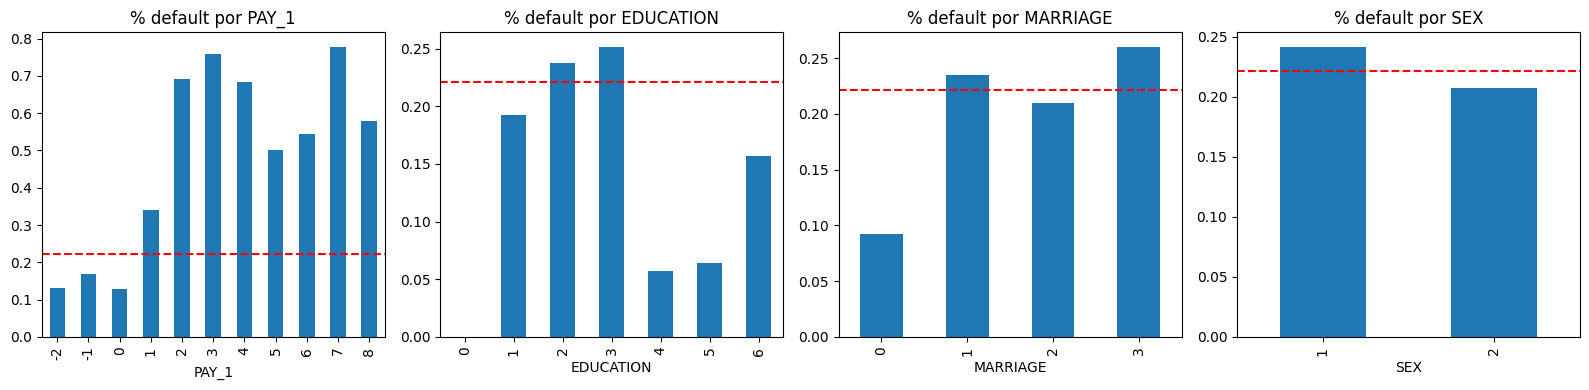

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ['PAY_1', 'EDUCATION', 'MARRIAGE', 'SEX']):
    df.groupby(col)['DEFAULT'].mean().plot(kind='bar', ax=ax, title=f'% default por {col}')
    ax.axhline(df['DEFAULT'].mean(), color='red', linestyle='--')  # promedio general
plt.tight_layout()
plt.show()

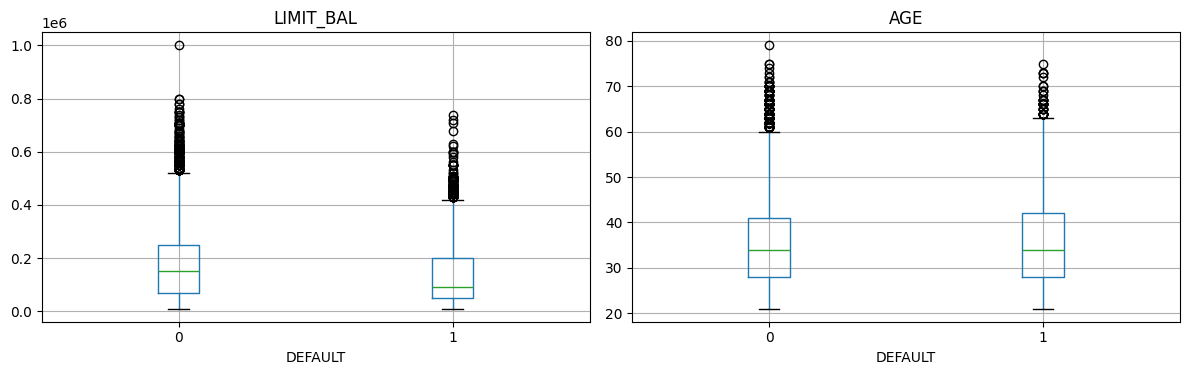

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['LIMIT_BAL', 'AGE']):
    df.boxplot(column=col, by='DEFAULT', ax=ax)
    ax.set_title(col)
plt.suptitle('')
plt.tight_layout()
plt.show()

Lo que más se relaciona con el default es el estado de pago del último mes (PAY_1, correlación
de 0,33). Los que están al día hacen default entre un 13% y un 17% de las veces; con un mes de
atraso sube a 34%, y con dos meses o más pasa el 50%. Además, cuanto más reciente es el mes,
más pesa: PAY_2 y PAY_3 tienen correlaciones más bajas.

El límite de crédito va al revés (-0,15): los que hacen default tienen límites más bajos.
Supongo que es porque el banco ya les da menos límite a los clientes que considera más riesgosos.

La edad y los montos facturados casi no tienen relación con el default.

Las facturas de los distintos meses están muy relacionadas entre sí (entre 0,89 y 0,95), así que
básicamente dicen lo mismo. Para el modelo conviene usar una sola o un promedio.

En sexo, estado civil y educación las diferencias son chicas, de 2 a 6 puntos. Los códigos raros
de EDUCATION tienen muy poco default, lo que me confirma que está bien juntarlos en "otros".
SEX no lo usaría para predecir: aporta poco y además usar el sexo para dar crédito puede ser
discriminatorio.

## 5. Conclusiones

Lo más importante que saqué del análisis:
1. El atraso en los pagos de los últimos meses es lo que mejor anticipa el default. Con dos meses
   o más de atraso, más de la mitad termina en default, contra un 13-17% de los que están al día.
2. A menor límite de crédito, más default.
3. Edad, sexo, estado civil y montos facturados, por sí solos, no dicen mucho.
4. No hay datos faltantes, pero hay códigos sin documentar en EDUCATION, MARRIAGE y PAY_X que
   hay que acomodar.

Qué implica para la etapa 2:
- Clasificación: es el caso más directo (predecir DEFAULT). Por el desbalance, voy a evaluar con
  recall y F1 y no con accuracy.
- Regresión: se puede predecir LIMIT_BAL, pero sin usar DEFAULT como variable, porque el límite
  se asigna antes de saber si el cliente paga o no. Sería usar información del futuro.
- Clustering: con los datos de pagos y facturación se pueden armar grupos de clientes, pero antes
  hay que escalar las variables. Si no, LIMIT_BAL (hasta 1.000.000) pesa mucho más que AGE (hasta 79).

Antes de modelar tengo que:
- Agrupar los códigos raros (EDUCATION 0, 5 y 6 en 4; MARRIAGE 0 en 3).
- Reducir la redundancia entre BILL_AMT1 y BILL_AMT6.
- Ver si aplico logaritmo a los montos.
- Decidir si dejo afuera SEX, por una cuestión ética.